# configuration & loadings

In [ ]:
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

plt.style.use("seaborn-v0_8")

In [6]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "gvns").exists():
    PROJECT_ROOT = Path(__file__).parent.parent.parent.parent if '__file__' in locals() else Path.cwd().parent.parent.parent

print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\HP\Documents\GitHub\GVNS-implementation


In [7]:
# Paths - relative to project root
DATA_PATH = PROJECT_ROOT / "gvns" / "ls_data" / "learning_dataset.csv"
MODEL_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_delta_regressor.pkl"
FEATURES_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_features.json"

# Load artifacts
model = joblib.load(MODEL_PATH)

with open(FEATURES_PATH) as f:
    feature_names = json.load(f)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Number of features:", len(feature_names))

Dataset shape: (6684, 32)
Number of features: 30


In [8]:
# rebuild the test set
df["log_delta"] = np.log1p(df["delta"].clip(lower=0)) # target

# Grouping variable
groups = df["source_file"]

X = df[feature_names]
y = df["log_delta"]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train instances:", groups.iloc[train_idx].nunique())
print("Test  instances:", groups.iloc[test_idx].nunique())

Train instances: 14
Test  instances: 4


In [9]:
df["log_delta"].describe(percentiles=[0.1, 0.5, 0.9, 0.99])

count    6684.000000
mean        2.573818
std         2.686743
min         0.000000
10%         0.227943
50%         2.021731
90%         4.620010
99%        15.201783
max        16.759927
Name: log_delta, dtype: float64

In [10]:
(df["delta"] < 1e-3).mean()

np.float64(0.057001795332136444)

so only ~5.7% of samples are effectively zero-improvement

If this had been:
- 30% → regression becomes unstable
- 50% → classification would be mandatory
- 70% → regression is almost pointless

But 5–6% means:
- Most LS calls produce some improvement
- Model is not dominated by degenerate targets
- MAE / RMSE are meaningful

# Baseline comparison
before trusting the RF, we need to compare against trivial predictors:
- Always predict 0
- Predict mean log-delta
- Predict mean per neighborhood
- Predict mean per strategy

we need to beat all of them, especially the per-neighborhood one
if not, features are insufficient

In [11]:
# RF predictions
y_pred = model.predict(X_test)

# Baselines
baseline_zero = np.zeros_like(y_test)
baseline_mean = np.full_like(y_test, y_train.mean())

# Metrics
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

print("RMSE comparison (log-delta):")
print(f"RF model     : {rmse(y_test, y_pred):.4f}")
print(f"Zero baseline: {rmse(y_test, baseline_zero):.4f}")
print(f"Mean baseline: {rmse(y_test, baseline_mean):.4f}")

RMSE comparison (log-delta):
RF model     : 2.2376
Zero baseline: 4.2954
Mean baseline: 3.1267


# global regression quality

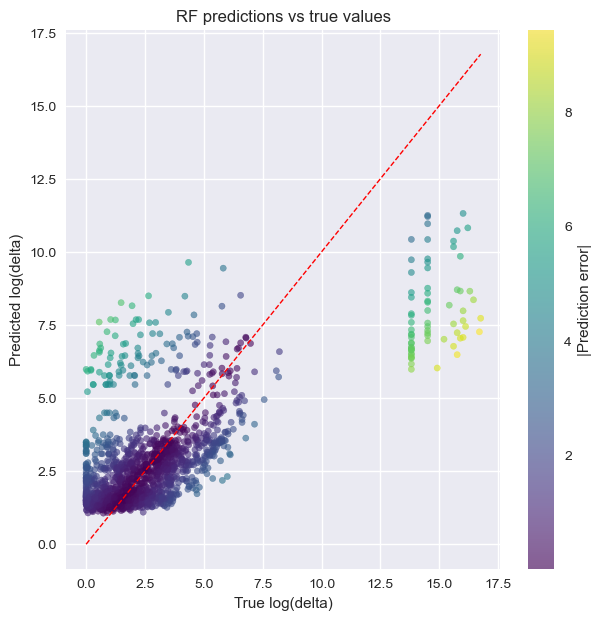

In [20]:
error = np.abs(y_test - y_pred)

plt.figure(figsize=(7, 7))
sc = plt.scatter(
    y_test,
    y_pred,
    c=error,
    cmap="viridis",
    alpha=0.6,
    s=20
)

# Diagonal reference
lims = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]
plt.plot(lims, lims, "r--", linewidth=1)

plt.colorbar(sc, label="|Prediction error|")
plt.xlabel("True log(delta)")
plt.ylabel("Predicted log(delta)")
plt.title("RF predictions vs true values")

plt.show()

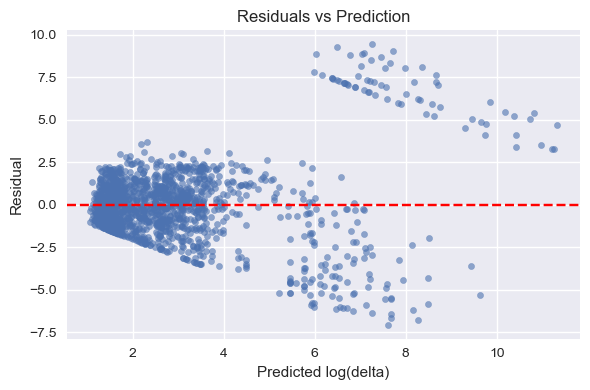

In [22]:
# residuals 
residuals = y_test - y_pred

plt.figure(figsize=(6, 4))
plt.scatter(
    y_pred, 
    residuals, 
    alpha=0.6, 
    s=20
    )
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted log(delta)")
plt.ylabel("Residual")
plt.title("Residuals vs Prediction")
plt.tight_layout()
plt.show()


# Errors

## error by neighborhood 

In [14]:
df_test = df.iloc[test_idx].copy()
df_test["pred_log_delta"] = y_pred
df_test["abs_error"] = np.abs(df_test["log_delta"] - df_test["pred_log_delta"])

neigh_error = (
    df_test
    .groupby("neigh_id")["abs_error"]
    .agg(["mean", "median", "count"])
    .sort_index()
)

neigh_error

,mean,median,count
neigh_id,,,
0,2.037165,1.428724,813
1,0.913359,0.850724,633
3,0.929030,0.870677,10
5,1.208560,0.992528,9
7,0.656524,0.623489,5


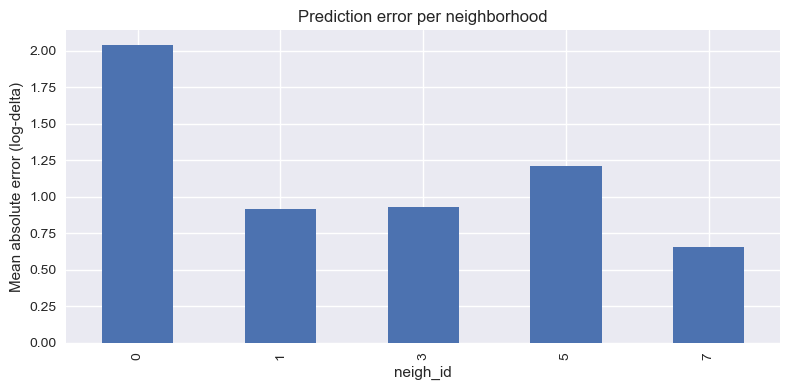

In [15]:
neigh_error["mean"].plot(kind="bar", figsize=(8, 4))
plt.ylabel("Mean absolute error (log-delta)")
plt.title("Prediction error per neighborhood")
plt.tight_layout()
plt.show()

## error by strategy
FI vs BI

In [16]:
strategy_error = (
    df_test
    .groupby("strategy")["abs_error"]
    .mean()
)

strategy_error

strategy
0    1.664685
1    1.138946
Name: abs_error, dtype: float64

# Learning curve

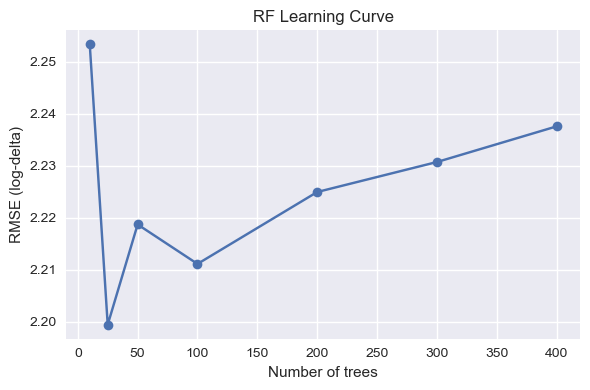

In [19]:
warnings.filterwarnings('ignore')

tree_counts = [10, 25, 50, 100, 200, 300, 400]
rmse_vals = []

for n in tree_counts:
    preds_n = np.mean(
        [tree.predict(X_test) for tree in model.estimators_[:n]],
        axis=0
    )
    rmse_vals.append(root_mean_squared_error(y_test, preds_n))

plt.figure(figsize=(6, 4))
plt.plot(tree_counts, rmse_vals, marker="o")
plt.xlabel("Number of trees")
plt.ylabel("RMSE (log-delta)")
plt.title("RF Learning Curve")
plt.tight_layout()
plt.show()